In [75]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import roc_auc_score

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [76]:
pd.__version__, np.__version__

('3.0.5', '2.5.2')

 ## Homework 4

> [!NOTE]
> This homework uses the pinned 2026 lead-scoring release in the course
> repository. The plan and report are available in `cohorts/2026/data/`.


In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).


In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not.

### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

In [77]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [78]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [79]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [81]:
categorical = list(df.select_dtypes(include=['str']).columns)
numerical = list(df.select_dtypes(include=['int64', 'float64']).columns)

del numerical[numerical.index('converted')]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [82]:
categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

In [83]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train['converted']
y_train = df_train['converted']
y_val = df_val['converted']
y_test = df_test['converted']

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`


In [84]:
scores = []

for n in numerical:
    score = 0.0

    score = roc_auc_score(y_train, df_train[n])

    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[n])

    scores.append((n, score))

scores

[('annual_income', 0.6081977776250831),
 ('number_of_courses_viewed', 0.7229894623989618),
 ('interaction_count', 0.7649203047563227),
 ('lead_score', 0.7882254810906102)]

#### Answer: `lead_score`

### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [85]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

round(roc_auc_score(y_val, y_pred), 3)

0.732

#### Answer: 0.732

### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

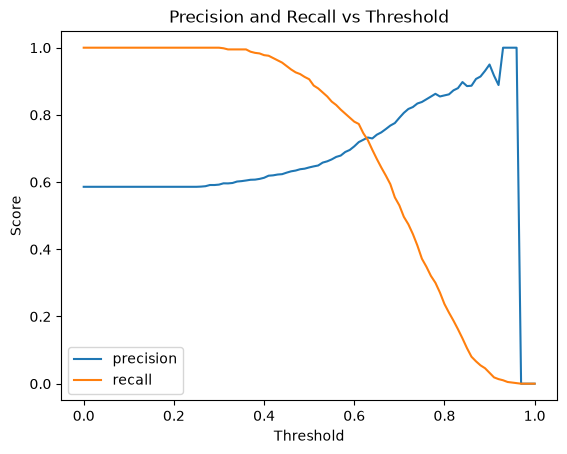

In [86]:
thresholds = np.linspace(0, 1, 101)

precisions = []
recalls = []

for t in thresholds:
    actual_positive = y_val == 1
    actual_negative = y_val == 0

    predict_positive = y_pred >= t
    predict_negative = y_pred < t

    tp = (actual_positive & predict_positive).sum()
    fp = (actual_negative & predict_positive).sum()

    tn = (actual_negative & predict_negative).sum()
    fn = (actual_positive & predict_negative).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0

    precisions.append(p)
    recalls.append(r)

plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()

In [87]:
df_scores = pd.DataFrame({
    'threshold': thresholds,
    'precision': precisions,
    'recall': recalls,
})

df_scores = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)]

df_scores['diff'] = (df_scores.precision - df_scores.recall).abs()

df_scores.sort_values('diff').head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


#### Answer: 0.63

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [88]:
df_scores['f1'] = np.array(2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall))

df_scores.sort_values('f1', ascending=False).head()

,threshold,precision,recall,diff,f1
41,0.41,0.619048,0.976109,0.357062,0.757616
42,0.42,0.620087,0.969283,0.349196,0.756325
43,0.43,0.622517,0.962457,0.339941,0.756032
45,0.45,0.628118,0.945392,0.317275,0.754768
44,0.44,0.623608,0.955631,0.332023,0.754717


#### Answer: 0.41

### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [89]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)

folds = kf.split(df_full_train)

scores = []

for train_idx, val_idx in folds:
    fold_df_train = df_full_train.iloc[train_idx]
    fold_df_val = df_full_train.iloc[val_idx]

    y_train = fold_df_train['converted']
    y_val = fold_df_val['converted']

    del fold_df_train['converted']
    del fold_df_val['converted']

    train_dicts = fold_df_train[categorical + numerical].to_dict(orient='records')
    X_train = dv.fit_transform(train_dicts)

    val_dicts = fold_df_val[categorical + numerical].to_dict(orient='records')
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]

    score = roc_auc_score(y_val, y_pred)
    scores.append(score)

print(f"Mean AUC: {np.mean(scores):.3f}")
print(f"Std AUC: {np.std(scores):.3f}")

Mean AUC: 0.732
Std AUC: 0.007


#### Answer: 0.007

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [90]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)

C_values = [0.000001, 0.001, 1]

for C in C_values:
    scores = []

    folds = kf.split(df_full_train)

    for train_idx, val_idx in folds:
        fold_df_train = df_full_train.iloc[train_idx]
        fold_df_val = df_full_train.iloc[val_idx]

        y_train = fold_df_train['converted']
        y_val = fold_df_val['converted']

        del fold_df_train['converted']
        del fold_df_val['converted']

        train_dicts = fold_df_train[categorical + numerical].to_dict(orient='records')
        X_train = dv.fit_transform(train_dicts)

        val_dicts = fold_df_val[categorical + numerical].to_dict(orient='records')
        X_val = dv.transform(val_dicts)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]

        score = roc_auc_score(y_val, y_pred)
        scores.append(score)

    print(f"C={str(C).ljust(5)}: Mean AUC: {np.mean(scores):.3f}, Std AUC: {np.std(scores):.3f}")

C=1e-06: Mean AUC: 0.617, Std AUC: 0.019
C=0.001: Mean AUC: 0.749, Std AUC: 0.010
C=1    : Mean AUC: 0.732, Std AUC: 0.007


#### Answer: 0.001

## Learning in Public

Share what you learned from this homework in a short post, screenshot, or
notebook excerpt. Use `#mlzoomcamp`, tag Alexey Grigorev or DataTalksClub, and
submit the post link with your homework. Don't share credentials, private
data, or other secrets.

See the [learning in public guide](https://datatalks.club/docs/courses/zoomcamp-logistics/learning-in-public/) for more
ideas and examples.

### Example post for LinkedIn

```text
🚀 Completed Module 4 of Machine Learning Zoomcamp 2026!

I evaluated a classifier with ROC AUC, precision, recall, and F1, then used
cross-validation to measure score variation and tune a parameter.

My repo: <LINK>

#mlzoomcamp @Alexey Grigorev
```

### Example post for X

```text
Evaluated a classifier in Module 4 of #mlzoomcamp.

✅ Compared ROC AUC and threshold-based metrics
✅ Found a useful precision/recall trade-off
✅ Used 5-fold cross-validation for tuning

My repo: <LINK>
```

## Submit the results

* Submit your results here: https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04
* The numerical options are calculated from the pinned 2026 release. Use the value that matches your calculation; do not choose a merely close value.